---

# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

*Eksperimen `dt_baseline_fe`: baseline Decision Tree (CART) from scratch dengan feature engineering.*

---

## Kelompok 17 DerbyCounty

- NIM - Nama
- NIM - Nama
- NIM - Nama
- NIM - Nama
- 13524093 - Reinsen Silitonga

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Data Preparation**](#4)
5. [**Modeling dan Validation**](#5)
6. [**Submission**](#6)

---

# Introduction <a name="1"></a>

---

## Overview

*Cristiano Ronaldo sedang membangun Ronaldo Hotel dan ingin tahu lebih awal tamu mana yang kemungkinan membatalkan pesanannya. Prediksi ini membantu penginapan merencanakan overbooking, mengirim pengingat, dan menyusun kebijakan pembatalan. Sistem harus memakai pembelajaran mesin klasik agar ringan secara komputasi.*

## Aim

*Notebook ini membangun baseline prediksi `is_canceled` dengan model from scratch, memvalidasinya dengan stratified k-fold, membandingkannya dengan scikit-learn, lalu menghasilkan file submission Kaggle.*

## Dataset

*Dataset berisi 27.373 pemesanan pada `train.csv` dan 6.844 pemesanan pada `test.csv`. Target `is_canceled` bernilai 1 jika pemesanan dibatalkan.*

**Attributes**

1.  `num_adults`, `num_children`          : Jumlah tamu dewasa dan anak
2.  `weekend_nights`, `weekday_nights`    : Jumlah malam akhir pekan dan hari kerja
3.  `meal_package`                        : Paket makan (Room Only, Breakfast, Half Board, Full Board)
4.  `needs_parking`                       : 1 jika butuh tempat parkir
5.  `room_category`                       : Kategori kamar Type A sampai Type G (tidak berurutan)
6.  `days_before_arrival`                 : Selisih hari antara pemesanan dan kedatangan
7.  `arrival_year`, `arrival_month`, `arrival_day` : Tanggal kedatangan
8.  `booking_channel`                     : Kanal pemesanan
9.  `is_returning_guest`                  : 1 jika tamu pernah menginap sebelumnya
10. `prior_cancellations`, `prior_completed_bookings` : Riwayat pemesanan tamu
11. `nightly_rate_idr`                    : Harga rata-rata per kamar per malam (IDR)
12. `special_requests`                    : Jumlah permintaan khusus
13. `is_canceled`                         : Target

## Approach

*Alur kerja mengikuti CRISP-DM. Preprocessing selalu di-fit pada data train saja lalu diterapkan ke data validasi atau test, sehingga train dan test tidak pernah digabung.*

```
train.csv, test.csv
    |
    +-- Data Understanding   : tipe data, missing value, duplikasi, distribusi target
         |
    +-- Data Preparation     : cleaning, feature engineering, encoding, scaling
         |
    +-- Modeling             : Decision Tree (CART) dan KNN from scratch
         |
    +-- Validation           : stratified 5-fold, Macro F1, tuning threshold
         |
    +-- Submission           : training ulang di seluruh train, prediksi test
```

*Metrik kompetisi adalah **Macro F1**, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Leaderboard public memakai sekitar 30% test, sedangkan peringkat akhir memakai 70% sisanya. Karena itu seluruh keputusan diambil dari skor validasi silang, bukan dari skor public.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook berjalan di CPU. Library yang dipakai hanya NumPy, pandas, Matplotlib, dan scikit-learn (khusus untuk perbandingan).

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

Model from scratch, preprocessing, dan fungsi bantu ditulis langsung di notebook ini (bagian **Kode From Scratch**), jadi notebook bisa dijalankan tanpa file lain.

In [2]:
import heapq
import math
import os
import pickle
import random
import time

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

## Kode From Scratch

Fungsi bantu (metrik, validasi silang, save/load), preprocessing, dan model from scratch.

In [ ]:
# Utilitas: save/load model, metrik evaluasi, dan validasi silang.

# Simpan objek model ke file pickle.
def save_model(model, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)


# Muat kembali model yang disimpan dengan save_model.
def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)


# Confusion matrix biner dalam bentuk [[TN, FP], [FN, TP]].
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


# F1 untuk kelas 0 dan kelas 1, hasilnya [f1_0, f1_1].
def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])


# Macro F1, rata-rata F1 kedua kelas (metrik resmi kompetisi).
def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())


# Proporsi prediksi yang benar.
def accuracy(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


# Cari threshold dengan Macro F1 tertinggi, dipakai pada prediksi out-of-fold.
def best_threshold(y_true, proba, grid=None):
    if grid is None:
        grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])


# Bagi indeks menjadi k fold dengan proporsi kelas sama, hasilnya list (train_idx, val_idx).
def stratified_kfold(y, n_splits=5, seed=42):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]


# Validasi silang yang mengembalikan probabilitas out-of-fold.
# Preprocessor di-fit ulang tiap fold hanya dengan data train fold tersebut.
def cross_val_proba(make_model, make_prep, df, y, folds):
    y = np.asarray(y)
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        prep = make_prep()
        X_tr = prep.fit_transform(df.iloc[tr_idx])
        X_va = prep.transform(df.iloc[va_idx])
        model = make_model()
        model.fit(X_tr, y[tr_idx])
        oof[va_idx] = model.predict_proba(X_va)
    return oof


# Macro F1 per fold dengan satu threshold, untuk melihat kestabilan model.
def fold_scores(y, proba, folds, threshold):
    y = np.asarray(y)
    pred = (proba >= threshold).astype(int)
    return np.array([macro_f1(y[va], pred[va]) for _, va in folds])

In [ ]:
# Preprocessing bersama untuk semua model: konstanta, cleaning, fitur turunan, dan BasePreprocessor.


TARGET = 'is_canceled'
ID_COL = 'id'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']


# Buang baris duplikat persis (fitur dan target). Hanya untuk data train.
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)


# Ubah nilai yang tidak masuk akal (num_adults = 0) menjadi missing.
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df


# Tambah fitur turunan per baris, aman dipakai pada train dan test secara terpisah.
def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.weekday.astype(float)
    df['arrival_dayofyear'] = arrival.dt.dayofyear.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df


# Dasar preprocessor tiap model, statistik dipelajari dari data train saja.
# Kelas turunan cukup override _fit_extra dan _transform_extra.
class BasePreprocessor:

    # feature_engineering: pakai add_features atau tidak; rare_min_count: batas kategori langka.
    def __init__(self, feature_engineering=True, rare_min_count=20, drop_cols=None):
        self.feature_engineering = feature_engineering
        self.rare_min_count = rare_min_count
        self.drop_cols = list(drop_cols or [])

    # Pelajari kolom dan kategori dari data train, lalu statistik khusus model.
    def fit(self, df):
        df = self._base(df)
        self.cat_cols_ = [c for c in CAT_COLS if c in df.columns]
        self.num_cols_ = [c for c in df.columns if c not in self.cat_cols_]
        self.keep_cats_ = {}
        for c in self.cat_cols_:
            counts = df[c].value_counts()
            self.keep_cats_[c] = sorted(counts[counts >= self.rare_min_count].index)
        self._fit_extra(self._group_rare(df))
        return self

    # Terapkan transformasi yang sudah dipelajari ke data validasi atau test.
    def transform(self, df):
        return self._transform_extra(self._group_rare(self._base(df)))

    # Gabungan fit lalu transform.
    def fit_transform(self, df):
        return self.fit(df).transform(df)

    # Statistik khusus model, default tidak ada.
    def _fit_extra(self, df):
        pass

    # Transformasi khusus model, default data dikembalikan apa adanya.
    def _transform_extra(self, df):
        return df

    # Tandai nilai janggal, tambah fitur turunan (opsional), buang kolom id dan target.
    def _base(self, df):
        df = mark_invalid(df)
        if self.feature_engineering:
            df = add_features(df)
        drop = [ID_COL, TARGET] + self.drop_cols
        return df.drop(columns=[c for c in drop if c in df.columns])

    # Ganti kategori yang tidak ada di daftar train menjadi 'Other'.
    def _group_rare(self, df):
        df = df.copy()
        for c in self.cat_cols_:
            known = df[c].isin(self.keep_cats_[c]) | df[c].isna()
            df.loc[~known, c] = 'Other'
        return df


# Preprocessor untuk Decision Tree.


# Default: NaN dan kategori teks dibiarkan karena pohon bisa menanganinya langsung, tanpa scaling.
# impute_num: None, 'median', 'mean', atau 'mode' untuk kolom numerik.
# impute_cat: None atau 'mode' untuk kolom kategorikal.
# Statistik imputasi dipelajari dari data train, termasuk untuk fitur turunan.
class TreePreprocessor(BasePreprocessor):

    def __init__(self, impute_num=None, impute_cat=None, **kwargs):
        super().__init__(**kwargs)
        self.impute_num = impute_num
        self.impute_cat = impute_cat

    # Simpan nilai pengisi per kolom dari data train.
    def _fit_extra(self, df):
        self.fill_ = {}
        if self.impute_num is not None:
            for c in self.num_cols_:
                col = df[c]
                if self.impute_num == 'median':
                    self.fill_[c] = col.median()
                elif self.impute_num == 'mean':
                    self.fill_[c] = col.mean()
                else:
                    self.fill_[c] = col.mode()[0]
        if self.impute_cat == 'mode':
            for c in self.cat_cols_:
                self.fill_[c] = df[c].mode()[0]

    # Isi missing value dengan nilai dari data train.
    def _transform_extra(self, df):
        fill = getattr(self, 'fill_', {})
        return df.fillna(fill) if fill else df


# Preprocessor untuk KNN.


# Indikator missing, imputasi median/modus, one-hot, lalu standardisasi.
class KNNPreprocessor(BasePreprocessor):

    # Pelajari median, modus, kolom hasil encoding, serta mean dan std dari data train.
    def _fit_extra(self, df):
        self.medians_ = df[self.num_cols_].median()
        self.modes_ = {c: df[c].mode().iloc[0] for c in self.cat_cols_}
        self.missing_cols_ = [c for c in df.columns if df[c].isna().any()]
        encoded = self._encode(df)
        self.columns_ = list(encoded.columns)
        self.means_ = encoded.mean()
        self.stds_ = encoded.std().replace(0, 1.0)

    # Encode lalu standardisasi dengan statistik dari train.
    def _transform_extra(self, df):
        encoded = self._encode(df).reindex(columns=self.columns_, fill_value=0.0)
        return (encoded - self.means_) / self.stds_

    # Indikator missing, imputasi, dan one-hot encoding.
    def _encode(self, df):
        out = pd.DataFrame(index=df.index)
        for c in self.missing_cols_:
            out[f'{c}_missing'] = df[c].isna().astype(float)
        out[self.num_cols_] = df[self.num_cols_].fillna(self.medians_)
        for c in self.cat_cols_:
            filled = df[c].fillna(self.modes_[c])
            for cat in self.keep_cats_[c] + ['Other']:
                out[f'{c}_{cat}'] = (filled == cat).astype(float)
        return out.astype(float)

In [ ]:
# Implementasi Decision Tree Learning (CART) from scratch untuk klasifikasi biner.


# Satu node pohon. Daun hanya memakai value (proporsi kelas 1) dan n_samples.
class Node:
    __slots__ = ('feature', 'threshold', 'is_cat', 'left_cats', 'seen_cats',
                 'missing_left', 'frac_left', 'left', 'right', 'value', 'n_samples', 'n_pos', 'gain')

    # Buat node dengan proporsi kelas 1 dan jumlah sampelnya.
    def __init__(self, value, n_samples):
        self.value = value
        self.n_samples = n_samples
        self.n_pos = None
        self.feature = None
        self.threshold = None
        self.is_cat = False
        self.left_cats = None
        self.seen_cats = None
        self.missing_left = True
        self.frac_left = None
        self.left = None
        self.right = None
        self.gain = 0.0

    # True jika node tidak punya anak.
    @property
    def is_leaf(self):
        return self.left is None


# Impurity gini atau entropy (log_loss sama dengan entropy) secara vektor dari jumlah positif dan total sampel.
def _impurity(pos, n, criterion):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    if criterion == 'gini':
        return 2.0 * p * (1.0 - p)
    # Entropy biner, dengan konvensi 0 * log(0) = 0
    q = 1.0 - p
    with np.errstate(divide='ignore', invalid='ignore'):
        h = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))
    return h


# P-value uji chi-square (df = 1) untuk tabel 2x2 cabang kiri/kanan x kelas 0/1.
def _chi2_p_value(nl, pl, nr, pr):
    n, pos = nl + nr, pl + pr
    denom = nl * nr * pos * (n - pos)
    if denom == 0:
        return 1.0
    chi2 = n * (pl * (nr - pr) - pr * (nl - pl)) ** 2 / denom
    # Distribusi chi-square df 1: P(X > x) = erfc(sqrt(x / 2))
    return math.erfc(math.sqrt(chi2 / 2.0))


# Nilai dengan total bobot terbesar (nilai paling umum).
def _weighted_mode(x, w):
    vals, inv = np.unique(x, return_inverse=True)
    return vals[int(np.argmax(np.bincount(inv, weights=w)))]


# CART biner: split numerik dengan threshold, kategori diurutkan berdasarkan proporsi kelas 1,
# missing value ditangani sesuai parameter missing (default: ke cabang dengan impurity terkecil).
class DecisionTree:
    # criterion: 'gini', 'entropy', 'log_loss' (sama dengan entropy), atau 'gain_ratio' (C4.5).
    # splitter: 'best' (titik potong terbaik) atau 'random' (satu titik potong acak per fitur, lalu pilih fitur terbaik).
    # max_features: jumlah fitur yang dicoba per simpul. None (semua), int, float (fraksi), 'sqrt', atau 'log2'.
    # min_samples_split, min_samples_leaf: int (jumlah sampel) atau float (fraksi dari jumlah data train).
    # max_leaf_nodes: jika diisi, pohon tumbuh best-first (split dengan penurunan impurity terbesar dulu)
    #   sampai jumlah daun mencapai nilai ini.
    # random_state: seed untuk splitter 'random' dan max_features.
    # min_impurity_decrease: penurunan impurity terbobot minimum agar split diterima.
    # max_p_value: jika diisi, split hanya dibuat jika p-value uji chi-square <= nilai ini.
    # missing: cara menangani missing value saat split.
    #   'default'         : missing ke cabang dengan impurity terkecil
    #   'node_mode'       : missing diberi nilai paling umum di simpul
    #   'node_mode_class' : saat training, nilai paling umum di simpul pada kelas yang sama;
    #                       saat prediksi kelas belum diketahui, jadi memakai nilai paling umum di simpul
    #   'fractional'      : C4.5, gain dikali proporsi data yang diketahui dan missing dibagi
    #                       ke kedua cabang dengan bobot pecahan
    # class_weight: None, 'balanced', atau angka bobot kelas 1 relatif terhadap kelas 0.
    # m_estimate: smoothing probabilitas daun, (pos + m * prior) / (n + m); 0 berarti tanpa smoothing.
    # ccp_alpha: jika > 0, pohon dipangkas dengan cost-complexity pruning setelah dibangun.
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0, max_p_value=None,
                 missing='default', class_weight=None, m_estimate=0.0, ccp_alpha=0.0,
                 splitter='best', max_features=None, max_leaf_nodes=None, random_state=None):
        self.criterion = criterion
        self.splitter = splitter
        self.max_features = max_features
        self.max_leaf_nodes = max_leaf_nodes
        self.random_state = random_state
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_p_value = max_p_value
        self.missing = missing
        self.class_weight = class_weight
        self.m_estimate = m_estimate
        self.ccp_alpha = ccp_alpha

    # ------------------------------------------------------------ training

    # Latih pohon. Kolom bertipe teks pada X dianggap kategorikal.
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.feature_names_ = list(X.columns)
        self.is_cat_ = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
        # Kamus kategori ke kode integer, dipelajari dari data train
        self.cat_maps_ = {}
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                cats = sorted(X[c].dropna().unique())
                self.cat_maps_[c] = {v: i for i, v in enumerate(cats)}

        self._X = self._to_array(X)
        self._y = np.asarray(y).astype(int)
        self.n_total_ = len(self._y)
        self.feature_importances_ = np.zeros(len(self.feature_names_))

        # Bobot awal per baris: semua 1, atau bobot kelas yang dinormalisasi agar totalnya tetap n
        w = np.ones(self.n_total_)
        if self.class_weight is not None:
            n_pos = self._y.sum()
            w1 = ((self.n_total_ - n_pos) / n_pos if self.class_weight == 'balanced'
                  else float(self.class_weight))
            w[self._y == 1] = w1
            w *= self.n_total_ / w.sum()
        self.prior_ = float(w @ self._y) / self.n_total_

        # Parameter float dibaca sebagai fraksi dari jumlah data train
        frac = lambda v: math.ceil(v * self.n_total_) if isinstance(v, float) else v
        self._min_split = frac(self.min_samples_split)
        self._min_leaf = frac(self.min_samples_leaf)
        self._n_feat = self._resolve_max_features(len(self.feature_names_))
        self._rng = np.random.default_rng(getattr(self, 'random_state', None))

        if getattr(self, 'max_leaf_nodes', None) is None:
            self.root_ = self._build(np.arange(self.n_total_), w, depth=0)
        else:
            self.root_ = self._build_best_first(np.arange(self.n_total_), w)

        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        del self._X, self._y, self._rng
        if self.ccp_alpha > 0:
            self.cost_complexity_prune(self.ccp_alpha)
        return self

    # Ubah DataFrame jadi array float: kategori jadi kode, missing jadi NaN, kategori baru jadi -2.
    def _to_array(self, X):
        out = np.empty((len(X), len(self.feature_names_)), dtype=float)
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                # Kategori yang tidak dikenal saat train diberi kode -2
                codes = X[c].map(self.cat_maps_[c])
                codes = codes.where(X[c].isna() | codes.notna(), -2)
                out[:, j] = codes.astype(float).to_numpy()
            else:
                out[:, j] = pd.to_numeric(X[c], errors='coerce').to_numpy(dtype=float)
        return out

    # Jumlah fitur yang dicoba per simpul sesuai max_features.
    def _resolve_max_features(self, n_features):
        mf = getattr(self, 'max_features', None)
        if mf is None:
            return n_features
        if mf == 'sqrt':
            return max(1, int(math.sqrt(n_features)))
        if mf == 'log2':
            return max(1, int(math.log2(n_features)))
        if isinstance(mf, float):
            return max(1, min(n_features, int(mf * n_features)))
        return max(1, min(n_features, int(mf)))

    # Bangun pohon secara rekursif (depth-first) dari indeks baris idx dengan bobot w.
    def _build(self, idx, w, depth):
        node = self._make_node(idx, w)
        split = self._find_split(node, idx, w, depth)
        if split is None:
            return node
        (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
        node.left = self._build(idx_l, w_l, depth + 1)
        node.right = self._build(idx_r, w_r, depth + 1)
        return node

    # Bangun pohon best-first: simpul dengan penurunan impurity terbesar dipecah lebih dulu,
    # berhenti saat jumlah daun mencapai max_leaf_nodes.
    def _build_best_first(self, idx, w):
        root = self._make_node(idx, w)
        heap, order, n_leaves = [], 0, 1

        def push(node, idx, w, depth):
            nonlocal order
            split = self._find_split(node, idx, w, depth)
            if split is not None:
                heapq.heappush(heap, (-split['weighted_gain'], order, node, split, depth))
                order += 1

        push(root, idx, w, 0)
        while heap and n_leaves < self.max_leaf_nodes:
            _, _, node, split, depth = heapq.heappop(heap)
            (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
            node.left, node.right = self._make_node(idx_l, w_l), self._make_node(idx_r, w_r)
            n_leaves += 1
            push(node.left, idx_l, w_l, depth + 1)
            push(node.right, idx_r, w_r, depth + 1)
        return root

    # Buat simpul daun dari baris idx: proporsi kelas 1 (dengan m-estimate jika diisi).
    def _make_node(self, idx, w):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)
        m = getattr(self, 'm_estimate', 0.0)
        value = pos / n if m == 0 else (pos + m * self.prior_) / (n + m)
        node = Node(value=value, n_samples=int(n) if n == int(n) else n)
        node.n_pos = pos
        return node

    # Cari split untuk simpul, None jika simpul harus jadi daun (pre-pruning atau tidak ada split valid).
    def _find_split(self, node, idx, w, depth):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)

        # Kondisi berhenti (pre-pruning)
        if (pos == 0 or pos == n
                or n < self._min_split
                or n < 2 * self._min_leaf
                or (self.max_depth is not None and depth >= self.max_depth)):
            return None

        best = self._best_split(idx, y, w)
        if best is None:
            return None

        gain, f, thr, left_cats, seen_cats, miss_left, miss_by_class = best
        # Penurunan impurity dibobot proporsi sampel node terhadap seluruh data
        weighted_gain = gain * n / self.n_total_
        if weighted_gain < self.min_impurity_decrease:
            return None

        x, is_cat = self._X[idx, f], self.is_cat_[f]
        frac_left = None
        if self.missing == 'fractional':
            # Baris yang diketahui ikut kondisi split, baris missing masuk ke kedua cabang
            unknown = np.isnan(x)
            known_left = ~unknown & self._cond(x, thr, left_cats, is_cat)
            frac_left = float(w[known_left].sum() / w[~unknown].sum())
            left_mask, right_mask = known_left | unknown, (~unknown & ~known_left) | unknown
            w_left = np.where(unknown, w * frac_left, w)[left_mask]
            w_right = np.where(unknown, w * (1.0 - frac_left), w)[right_mask]
        else:
            go_left = self._go_left(x, thr, left_cats, seen_cats, miss_left, is_cat)
            if miss_by_class is not None:
                # Saat training, missing diarahkan sesuai nilai paling umum pada kelasnya
                go_left = np.where(np.isnan(x), np.where(y == 1, miss_by_class[1], miss_by_class[0]),
                                   go_left)
            left_mask, right_mask = go_left, ~go_left
            w_left, w_right = w[go_left], w[~go_left]

        if self.max_p_value is not None:
            nl, pl = float(w_left.sum()), float(w_left @ y[left_mask])
            if _chi2_p_value(nl, pl, n - nl, pos - pl) > self.max_p_value:
                return None
        return dict(gain=gain, weighted_gain=weighted_gain, feature=f, threshold=thr, is_cat=bool(is_cat),
                    left_cats=left_cats, seen_cats=seen_cats, missing_left=miss_left, frac_left=frac_left,
                    left=(idx[left_mask], w_left), right=(idx[right_mask], w_right))

    # Simpan split pada simpul, tambah feature importance, kembalikan (idx, w) cabang kiri dan kanan.
    def _apply_split(self, node, split):
        node.feature, node.threshold = split['feature'], split['threshold']
        node.is_cat = split['is_cat']
        node.left_cats, node.seen_cats = split['left_cats'], split['seen_cats']
        node.missing_left = split['missing_left']
        node.frac_left = split['frac_left']
        node.gain = split['gain']
        self.feature_importances_[split['feature']] += split['weighted_gain']
        return split['left'], split['right']

    # Cari split terbaik dari semua fitur, None jika tidak ada split valid.
    def _best_split(self, idx, y, w):
        n = float(w.sum())
        wy = w * y
        parent = _impurity(wy.sum(), n, self.criterion)
        best_gain, best = 1e-12, None
        candidates = []

        n_features = self._X.shape[1]
        features = (range(n_features) if self._n_feat >= n_features
                    else np.sort(self._rng.choice(n_features, self._n_feat, replace=False)))
        random_split = getattr(self, 'splitter', 'best') == 'random'

        for f in features:
            x = self._X[idx, f]
            miss = np.isnan(x)
            w_miss, pos_miss = float(w[miss].sum()), float(wy[miss].sum())
            xv, yv, wv = x[~miss], y[~miss], w[~miss]
            if len(xv) < 2:
                continue

            if self.is_cat_[f]:
                # Urutkan kategori berdasarkan proporsi positif, lalu ganti nilai x dengan peringkatnya
                cats, inv = np.unique(xv, return_inverse=True)
                if len(cats) < 2:
                    continue
                cnt = np.bincount(inv, weights=wv)
                pos_rate = np.bincount(inv, weights=wv * yv) / cnt
                order = np.argsort(pos_rate, kind='mergesort')
                rank = np.empty(len(cats), dtype=int)
                rank[order] = np.arange(len(cats))
                xv = rank[inv].astype(float)

            sort = np.argsort(xv, kind='mergesort')
            xs, ys, ws = xv[sort], yv[sort], wv[sort]
            # Kandidat titik potong: hanya di antara dua nilai yang berbeda
            cut = np.where(xs[:-1] != xs[1:])[0]
            if len(cut) == 0:
                continue
            cum_w = np.cumsum(ws)
            cum_pos = np.cumsum(ws * ys)
            n_left = cum_w[cut]
            p_left = cum_pos[cut]
            w_known, pos_known = cum_w[-1], cum_pos[-1]
            # splitter random: hanya satu titik potong acak yang dinilai untuk fitur ini
            pick_cut = int(self._rng.integers(len(cut))) if random_split else None

            # Tiap opsi: (missing kelas 0 ke kiri, missing kelas 1 ke kiri, arah missing saat prediksi)
            if self.missing == 'fractional':
                options = [None]
            elif self.missing in ('node_mode', 'node_mode_class'):
                mode_left = xs[cut] >= _weighted_mode(xs, ws)
                if self.missing == 'node_mode':
                    options = [(mode_left, mode_left, mode_left)]
                else:
                    # Kelas yang tidak punya data diketahui memakai nilai paling umum di simpul
                    by_class = []
                    for c in (0, 1):
                        m = ys == c
                        by_class.append(xs[cut] >= _weighted_mode(xs[m], ws[m]) if m.any() else mode_left)
                    options = [(by_class[0], by_class[1], mode_left)]
            else:
                options = [(True, True, True), (False, False, False)] if w_miss > 0 else [(True, True, True)]

            for opt in options:
                if opt is None:
                    # C4.5: gain dihitung dari data yang diketahui lalu dikali proporsinya
                    nl, pl = n_left, p_left
                    nr, pr = w_known - n_left, pos_known - p_left
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / w_known
                    known_parent = _impurity(pos_known, w_known, self.criterion)
                    gain = np.where(valid, (w_known / n) * (known_parent - child), -np.inf)
                    split_total = w_known
                    miss_pred = True
                else:
                    ml0, ml1, miss_pred = opt
                    nl = n_left + ml0 * (w_miss - pos_miss) + ml1 * pos_miss
                    pl = p_left + ml1 * pos_miss
                    nr = (w_known + w_miss) - nl
                    pr = (pos_known + pos_miss) - pl
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / n
                    gain = np.where(valid, parent - child, -np.inf)
                    split_total = n

                # Hasil split untuk titik potong ke-i
                def make_split(i, g):
                    pick = lambda v: bool(v[i]) if isinstance(v, np.ndarray) else bool(v)
                    miss_left = pick(miss_pred)
                    by_class = ((pick(opt[0]), pick(opt[1])) if self.missing == 'node_mode_class'
                                and opt is not None else None)
                    if self.is_cat_[f]:
                        # Kategori dengan peringkat <= titik potong masuk ke kiri
                        left_cats = cats[order[: int(xs[cut[i]]) + 1]]
                        return (g, f, None, left_cats, cats, miss_left, by_class)
                    thr = (xs[cut[i]] + xs[cut[i] + 1]) / 2.0
                    return (g, f, thr, None, None, miss_left, by_class)

                if self.criterion == 'gain_ratio':
                    # C4.5: gain ratio hanya untuk titik potong dengan gain >= rata-rata gain
                    ok = gain > 1e-12
                    if not ok.any():
                        continue
                    ok &= gain >= gain[ok].mean() - 1e-12
                    split_info = _impurity(nl, np.full_like(nl, split_total), 'entropy')
                    ratio = np.where(ok, gain / np.maximum(split_info, 1e-12), -np.inf)
                    i = int(np.argmax(ratio))
                    candidates.append((float(ratio[i]), make_split(i, float(gain[i]))))
                    continue

                i = int(np.argmax(gain))
                if gain[i] > best_gain:
                    best_gain = float(gain[i])
                    best = make_split(i, best_gain)

        if self.criterion == 'gain_ratio' and candidates:
            # Antar atribut: pilih gain ratio terbesar dari atribut dengan gain >= rata-rata
            avg_gain = np.mean([s[0] for _, s in candidates])
            ratio, best = max((c for c in candidates if c[1][0] >= avg_gain - 1e-12), key=lambda c: c[0])
        return best

    # Tentukan baris yang masuk cabang kiri. Missing dan kategori tak dikenal ikut arah default.
    @staticmethod
    def _go_left(x, thr, left_cats, seen_cats, miss_left, is_cat):
        if is_cat:
            # Missing dan kategori yang tidak pernah terlihat di node ini ikut arah default
            unknown = np.isnan(x) | ~np.isin(x, seen_cats)
            return np.where(unknown, miss_left, np.isin(x, left_cats))
        return np.where(np.isnan(x), miss_left, x <= thr)

    # Kondisi split untuk nilai yang diketahui, True berarti masuk cabang kiri.
    @staticmethod
    def _cond(x, thr, left_cats, is_cat):
        if is_cat:
            return np.isin(x, left_cats)
        with np.errstate(invalid='ignore'):
            return x <= thr

    # ------------------------------------------------------------ pruning

    # Reduced-error pruning dari bawah ke atas: subtree diganti daun jika error validasi tidak naik.
    # Label daun memakai threshold (default 0.5 = kelas mayoritas).
    def prune(self, X_val, y_val, threshold=0.5):
        if getattr(self, 'missing', 'default') == 'fractional':
            raise NotImplementedError('prune belum mendukung missing fractional')
        Xa = self._to_array(pd.DataFrame(X_val))
        yv = np.asarray(y_val).astype(int)

        # Kembalikan jumlah error validasi pada subtree node setelah anak-anaknya dipangkas.
        def visit(node, idx):
            leaf_err = int(np.sum(yv[idx] != int(node.value >= threshold)))
            if node.is_leaf:
                return leaf_err
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            sub_err = visit(node.left, idx[go_left]) + visit(node.right, idx[~go_left])
            if leaf_err <= sub_err:
                node.left = node.right = None
                node.feature = None
                return leaf_err
            return sub_err

        visit(self.root_, np.arange(len(yv)))
        self._recompute_importances()
        return self

    # Cost-complexity pruning (CART): untuk alpha tertentu, cari subtree dengan
    # R(T) + alpha * |daun| terkecil. R dihitung dari impurity daun yang dibobot proporsi sampel.
    def cost_complexity_prune(self, alpha):
        crit = 'gini' if self.criterion == 'gini' else 'entropy'

        # Kembalikan (R subtree terbaik, jumlah daun) setelah anak-anaknya dipangkas.
        def visit(node):
            r_leaf = node.n_samples / self.n_total_ * float(
                _impurity(node.n_pos, node.n_samples, crit))
            if node.is_leaf:
                return r_leaf, 1
            r_left, n_left = visit(node.left)
            r_right, n_right = visit(node.right)
            r_sub, n_sub = r_left + r_right, n_left + n_right
            if r_leaf + alpha <= r_sub + alpha * n_sub:
                node.left = node.right = None
                node.feature = None
                return r_leaf, 1
            return r_sub, n_sub

        visit(self.root_)
        self._recompute_importances()
        return self

    # Hitung ulang feature importance dari split yang masih tersisa.
    def _recompute_importances(self):
        imp = np.zeros(len(self.feature_names_))
        stack = [self.root_]
        while stack:
            node = stack.pop()
            if node.is_leaf:
                continue
            imp[node.feature] += node.gain * node.n_samples / self.n_total_
            stack += [node.left, node.right]
        total = imp.sum()
        self.feature_importances_ = imp / total if total > 0 else imp

    # ------------------------------------------------------------ prediksi

    # Probabilitas kelas 1 (proporsi kelas 1 di daun) untuk tiap baris.
    def predict_proba(self, X):
        Xa = self._to_array(pd.DataFrame(X))
        if getattr(self, 'missing', 'default') == 'fractional':
            return self._predict_fractional(Xa)
        out = np.empty(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)))]
        while stack:
            node, idx = stack.pop()
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.value
                continue
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            stack.append((node.left, idx[go_left]))
            stack.append((node.right, idx[~go_left]))
        return out

    # Prediksi C4.5: baris yang missing di simpul diteruskan ke kedua cabang dengan bobot frac_left,
    # hasilnya rata-rata terbobot dari daun yang dicapai.
    def _predict_fractional(self, Xa):
        out = np.zeros(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)), np.ones(len(Xa)))]
        while stack:
            node, idx, w = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf:
                out[idx] += w * node.value
                continue
            x = Xa[idx, node.feature]
            # Missing dan kategori yang tidak pernah terlihat di simpul ini dianggap tidak diketahui
            unknown = np.isnan(x) | (~np.isin(x, node.seen_cats) if node.is_cat else False)
            left = ~unknown & self._cond(x, node.threshold, node.left_cats, node.is_cat)
            right = ~unknown & ~left
            stack.append((node.left, np.concatenate([idx[left], idx[unknown]]),
                          np.concatenate([w[left], w[unknown] * node.frac_left])))
            stack.append((node.right, np.concatenate([idx[right], idx[unknown]]),
                          np.concatenate([w[right], w[unknown] * (1.0 - node.frac_left)])))
        return out

    # Label 0/1 berdasarkan threshold.
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # ------------------------------------------------------------ inspeksi

    # Kedalaman pohon hasil training.
    def get_depth(self):
        def depth(node):
            return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
        return depth(self.root_)

    # Jumlah daun pohon.
    def get_n_leaves(self):
        def leaves(node):
            return 1 if node.is_leaf else leaves(node.left) + leaves(node.right)
        return leaves(self.root_)

    # Teks kondisi split sebuah node, misalnya 'days_before_arrival <= 150.5'.
    def describe_split(self, node):
        name = self.feature_names_[node.feature]
        if node.is_cat:
            inv = {v: k for k, v in self.cat_maps_[name].items()}
            cats = ', '.join(str(inv[int(c)]) for c in node.left_cats)
            return f'{name} in {{{cats}}}'
        return f'{name} <= {node.threshold:.4g}'

In [ ]:
# Implementasi KNN from scratch untuk klasifikasi biner.


# KNN dengan jarak Minkowski (p=1 Manhattan, p=2 Euclidean), input harus numerik dan sudah di-scaling.
class KNN:

    # weights: 'uniform' atau 'distance'; batch_size: jumlah query per hitungan jarak.
    def __init__(self, k=5, p=2, weights='uniform', batch_size=256):
        self.k = k
        self.p = p
        self.weights = weights
        self.batch_size = batch_size

    # Lazy learner, training cukup menyimpan data.
    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y).astype(int)
        return self

    # Jarak setiap baris Q ke seluruh data train.
    def _distances(self, Q):
        if self.p == 2:
            # ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab, lebih cepat dari selisih langsung
            sq = (Q ** 2).sum(1)[:, None] + (self.X_ ** 2).sum(1)[None, :] - 2.0 * Q @ self.X_.T
            return np.sqrt(np.maximum(sq, 0.0))
        diff = np.abs(Q[:, None, :] - self.X_[None, :, :])
        return (diff ** self.p).sum(2) ** (1.0 / self.p)

    # Cari k tetangga terdekat, hasilnya (jarak, indeks) terurut dari yang terdekat.
    def kneighbors(self, X, k=None):
        k = k or self.k
        X = np.asarray(X, dtype=float)
        bs = self.batch_size if self.p == 2 else max(1, self.batch_size // 16)
        all_d, all_i = [], []
        for s in range(0, len(X), bs):
            d = self._distances(X[s:s + bs])
            part = np.argpartition(d, k - 1, axis=1)[:, :k]
            dk = np.take_along_axis(d, part, axis=1)
            order = np.argsort(dk, axis=1, kind='mergesort')
            all_i.append(np.take_along_axis(part, order, axis=1))
            all_d.append(np.take_along_axis(dk, order, axis=1))
        return np.vstack(all_d), np.vstack(all_i)

    # Probabilitas kelas 1 dari hasil kneighbors, bisa dipakai ulang untuk k yang lebih kecil.
    def proba_from_neighbors(self, dist, idx, k=None):
        k = k or self.k
        dist, idx = dist[:, :k], idx[:, :k]
        labels = self.y_[idx]
        if self.weights == 'distance':
            w = 1.0 / (dist + 1e-9)
            return (w * labels).sum(1) / w.sum(1)
        return labels.mean(1)

    # Probabilitas kelas 1, yaitu proporsi (terbobot) tetangga berlabel 1.
    def predict_proba(self, X):
        dist, idx = self.kneighbors(X)
        return self.proba_from_neighbors(dist, idx)

    # Label 0/1 berdasarkan threshold.
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## Settings

Path data, jumlah fold, dan hyperparameter model final dikumpulkan di sini.

In [3]:
class Settings:
    SEED       = 42
    N_FOLDS    = 5

    # Hyperparameter final Decision Tree, dipilih dari grid search di bagian 5.2
    DT_PARAMS  = dict(criterion='gini', max_depth=12, min_samples_leaf=10)

    EXP_NAME   = 'dt_baseline_fe'
    MODEL_PATH = f'{EXP_NAME}.pkl'
    SUB_PATH   = f'submission_{EXP_NAME}.csv'

CFG = Settings()

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

#### Catatan

> Decision Tree from scratch bersifat deterministik karena tidak memakai sampling acak. Seed tetap dipasang karena pembagian fold pada validasi silang memakai pengacakan.

## Load Dataset

Kolom `id` dibaca sebagai teks karena sebagian id hanya berisi angka atau terlihat seperti notasi ilmiah.

In [5]:
train_raw = pd.read_csv('train.csv', dtype={'id': str})
test_raw  = pd.read_csv('test.csv', dtype={'id': str})
sample    = pd.read_csv('sample_submission.csv', dtype={'id': str})

print('train ', train_raw.shape)
print('test  ', test_raw.shape)
print('sample', sample.shape)

train  (27373, 19)
test   (6844, 18)
sample (6844, 2)


---

# Data Understanding <a name="3"></a>

---

## 3.1 Ukuran dan Tipe Data

Terdapat 17 fitur, 3 di antaranya kategorikal. Kolom yang memiliki nilai kosong terbaca sebagai `float64`.

In [6]:
train_raw.dtypes

id                              str
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking               float64
room_category                   str
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64
dtype: object

## 3.2 Missing Value, Duplikasi, dan Nilai Janggal

Selain nilai kosong, dihitung juga baris duplikat dan nilai yang tidak masuk akal, misalnya pemesanan tanpa tamu dewasa atau harga nol.

In [7]:
missing = pd.DataFrame({
    'train_%': train_raw.isna().mean() * 100,
    'test_%' : test_raw.isna().mean() * 100,
}).round(2)
print(missing[missing['train_%'] > 0])

feature_cols = [c for c in train_raw.columns if c != 'id']
print()
print('duplikat (fitur + target) ', train_raw.duplicated(subset=feature_cols).sum())
print('num_adults == 0           ', (train_raw['num_adults'] == 0).sum())
print('nightly_rate_idr == 0     ', (train_raw['nightly_rate_idr'] == 0).sum())
print('total malam == 0          ', ((train_raw['weekend_nights'] + train_raw['weekday_nights']) == 0).sum())

                     train_%  test_%
days_before_arrival     4.10    4.24
meal_package            6.43    6.46
needs_parking           3.95    3.61
nightly_rate_idr        7.45    7.89
num_adults              2.96    2.63
num_children           11.09   10.91
room_category           3.66    3.54
special_requests        9.13    8.66

duplikat (fitur + target)  64
num_adults == 0            106
nightly_rate_idr == 0      413
total malam == 0           64


#### Insights

> Delapan kolom memiliki missing value antara 3% dan 11%, dengan proporsi yang hampir sama di train dan test, sehingga kosongnya data kemungkinan acak dan bukan pola khusus test. Ada 64 baris duplikat persis, 106 pemesanan tanpa tamu dewasa, dan 413 pemesanan berharga 0 yang sebagian besar berasal dari kanal Complimentary.

## 3.3 Distribusi Target

Proporsi kelas menentukan apakah data perlu penanganan ketidakseimbangan.

In [8]:
print(train_raw[TARGET].value_counts())
print(train_raw[TARGET].value_counts(normalize=True).round(4))

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    0.6723
1    0.3277
Name: proportion, dtype: float64


#### Insights

> Sekitar 32,8% pemesanan dibatalkan. Data tidak seimbang tetapi tidak ekstrem, sehingga Macro F1 tetap perlu dijaga dengan memilih threshold, bukan sekadar memakai 0,5.

## 3.4 Statistik Ringkas

Statistik deskriptif fitur numerik untuk melihat rentang dan kemencengan data.

In [9]:
train_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.82,0.38,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.40,3.07,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.54,8.77,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0


#### Insights

> `days_before_arrival`, `prior_cancellations`, `prior_completed_bookings`, dan `num_children` sangat right-skewed. Sebagian besar data berasal dari tahun 2024. Rentang `nightly_rate_idr` jauh lebih besar dari fitur lain, jadi model berbasis jarak wajib memakai scaling.

## 3.5 Tingkat Pembatalan per Kategori

Tingkat pembatalan dihitung untuk setiap nilai fitur kategorikal dan beberapa fitur diskrit.

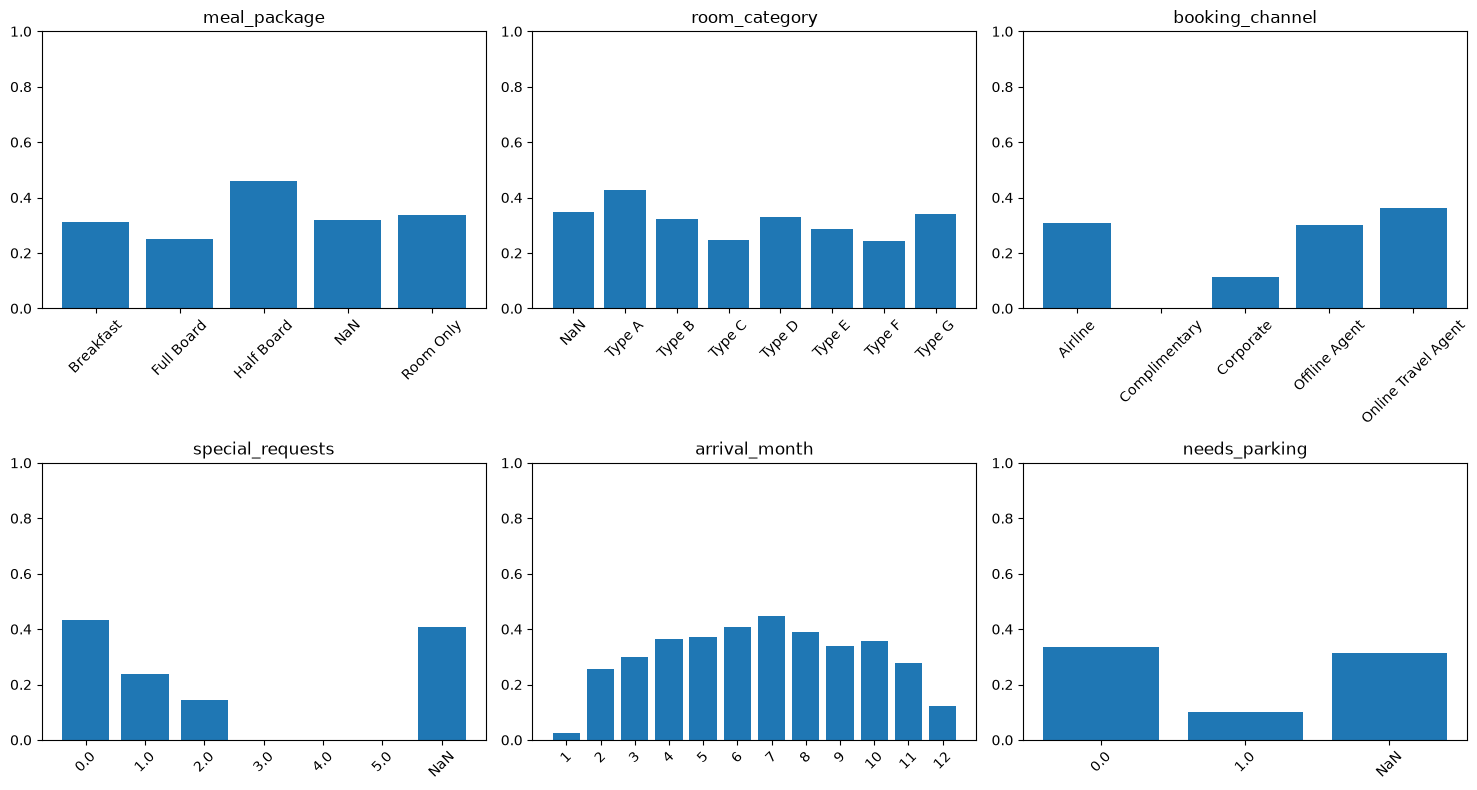

In [10]:
cols = CAT_COLS + ['special_requests', 'arrival_month', 'needs_parking']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cols):
    rate = train_raw.groupby(train_raw[c].astype('object').fillna('NaN'))[TARGET].agg(['mean', 'size'])
    ax.bar(rate.index.astype(str), rate['mean'])
    ax.set_title(c)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Insights

> `special_requests` adalah sinyal paling kuat: tanpa permintaan khusus 43% batal, sedangkan 3 permintaan atau lebih tidak pernah batal. Kanal Complimentary tidak pernah batal dan Corporate hanya 11,5%. Pembatalan tertinggi terjadi di pertengahan tahun (Juni sampai Agustus) dan terendah di Januari serta Desember. Tamu yang butuh parkir jarang membatalkan (10%).

## 3.6 Lead Time dan Harga

Distribusi `days_before_arrival` dan `nightly_rate_idr` dibandingkan antara pemesanan batal dan tidak batal.

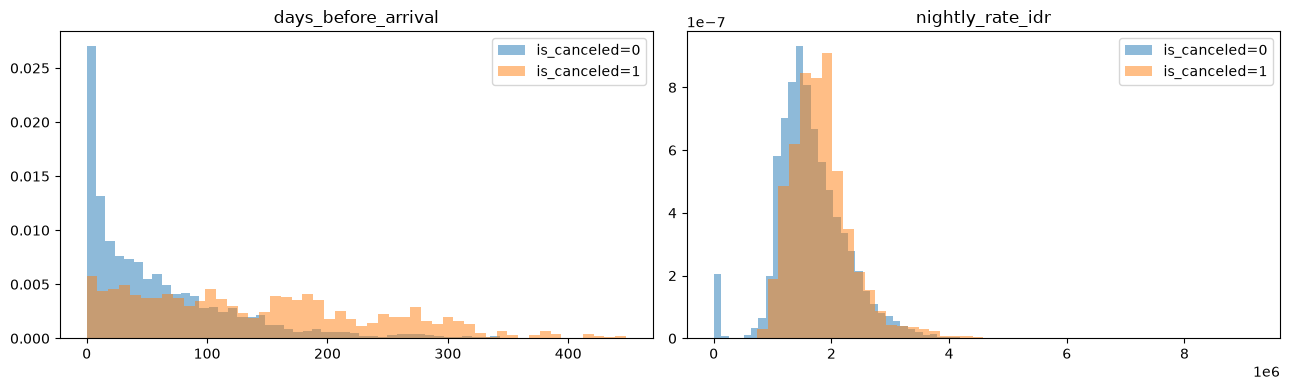

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ['days_before_arrival', 'nightly_rate_idr']):
    for label in [0, 1]:
        ax.hist(train_raw.loc[train_raw[TARGET] == label, c].dropna(), bins=50,
                alpha=0.5, density=True, label=f'is_canceled={label}')
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

#### Insights

> Pemesanan yang batal memiliki median `days_before_arrival` 123 hari, jauh di atas 38 hari untuk yang tidak batal. Harga pemesanan yang batal juga sedikit lebih tinggi. Kedua fitur ini kontinu sehingga cocok dipecah dengan threshold pada Decision Tree.

---

# Data Preparation <a name="4"></a>

---

## 4.1 Data Cleaning

Baris yang duplikat persis (fitur dan target sama) dibuang dari train karena tidak menambah informasi dan membuat validasi terlalu optimis. Data test tidak dibuang barisnya karena setiap id wajib punya prediksi.

In [12]:
train = clean_train(train_raw)
y = train[TARGET].to_numpy()
print('sebelum', train_raw.shape, ' sesudah', train.shape)

sebelum (27373, 19)  sesudah (27309, 19)


## 4.2 Feature Engineering

Fitur turunan dihitung per baris pada fungsi `add_features`, sehingga aman dipakai pada train dan test secara terpisah. Sebelumnya, fungsi `mark_invalid` mengubah `num_adults = 0` menjadi missing.

| Fitur | Keterangan |
| --- | --- |
| `total_nights` | `weekend_nights + weekday_nights` |
| `total_guests` | `num_adults + num_children` |
| `is_free` | 1 jika harga 0 (menginap gratis) |
| `rate_per_guest` | harga per malam dibagi jumlah tamu |
| `arrival_weekday` | hari kedatangan (0 Senin, 6 Minggu) |
| `arrival_dayofyear` | hari ke berapa dalam tahun |
| `arrival_index` | jumlah hari sejak 1 Januari 2023, menangkap tren waktu |

In [13]:
new_cols = ['total_nights', 'total_guests', 'is_free', 'rate_per_guest',
            'arrival_weekday', 'arrival_dayofyear', 'arrival_index']
add_features(mark_invalid(train))[new_cols + [TARGET]].head()

,total_nights,total_guests,is_free,rate_per_guest,arrival_weekday,arrival_dayofyear,arrival_index,is_canceled
0,3,NaN,0.0,NaN,2.0,94.0,458.0,1
1,3,2.0,NaN,NaN,1.0,213.0,212.0,0
2,3,3.0,0.0,6.996667e+05,2.0,241.0,605.0,1
3,3,3.0,0.0,5.643333e+05,1.0,226.0,590.0,0
4,1,2.0,0.0,1.005000e+06,6.0,245.0,609.0,0


## 4.3 Data Transformation

Setiap model punya preprocessor sendiri yang diturunkan dari `BasePreprocessor` (`src/preprocessing/common.py`). Statistik dipelajari dari data train lalu diterapkan ke data lain. Kategori dengan kurang dari 20 kemunculan digabung menjadi `Other`.

| Kelas | Dipakai oleh | Isi transformasi |
| --- | --- | --- |
| `TreePreprocessor` | Decision Tree | NaN dibiarkan, kategori tetap teks, tanpa scaling |
| `KNNPreprocessor` | KNN | imputasi median/modus, indikator missing, one-hot, standardisasi |

Decision Tree from scratch dapat memproses NaN dan kategori secara langsung, sehingga tidak perlu imputasi maupun scaling.

In [14]:
prep_tree = TreePreprocessor().fit(train)
prep_scaled = KNNPreprocessor().fit(train)

X_tree = prep_tree.transform(train)
X_scaled = prep_scaled.transform(train)
print('tree  ', X_tree.shape, ' NaN tersisa', int(X_tree.isna().sum().sum()))
print('scaled', X_scaled.shape, ' NaN tersisa', int(X_scaled.isna().sum().sum()))
print('kategori yang disimpan', prep_tree.keep_cats_)

tree   (27309, 24)  NaN tersisa 24842
scaled (27309, 49)  NaN tersisa 0
kategori yang disimpan {'meal_package': ['Breakfast', 'Half Board', 'Room Only'], 'room_category': ['Type A', 'Type B', 'Type C', 'Type D', 'Type F', 'Type G'], 'booking_channel': ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']}


#### Pertanyaan

> Mengapa ketidakseimbangan kelas tidak ditangani dengan oversampling?

> Rasio kelas sekitar 2 banding 1, tidak terlalu ekstrem. Model menghasilkan probabilitas sehingga ketidakseimbangan cukup ditangani dengan memilih threshold yang memaksimalkan Macro F1 pada prediksi out-of-fold. Cara ini tidak menambah data sintetis yang bisa membuat validasi bias.

---

# Modeling dan Validation <a name="5"></a>

---

## 5.1 Skema Validasi

Data train dibagi menjadi 5 fold secara stratified. Pada setiap fold, preprocessor dan model di-fit ulang hanya dengan 4 fold lainnya. Gabungan prediksi dari setiap fold validasi disebut prediksi out-of-fold (OOF) dan dipakai untuk memilih hyperparameter dan threshold.

In [15]:
folds = stratified_kfold(y, n_splits=CFG.N_FOLDS, seed=CFG.SEED)
for k, (tr_idx, va_idx) in enumerate(folds):
    print(f'fold {k}  train {len(tr_idx):>6}  val {len(va_idx):>5}  rasio batal val {y[va_idx].mean():.4f}')


# Ringkas hasil OOF: threshold terbaik, Macro F1 OOF, rata-rata dan std per fold.
def report(name, oof):
    thr, score = best_threshold(y, oof)
    per_fold = fold_scores(y, oof, folds, thr)
    return dict(model=name, threshold=thr, oof_macro_f1=round(score, 4),
                fold_mean=round(float(per_fold.mean()), 4), fold_std=round(float(per_fold.std()), 4))

fold 0  train  21847  val  5462  rasio batal val 0.3275
fold 1  train  21847  val  5462  rasio batal val 0.3275
fold 2  train  21847  val  5462  rasio batal val 0.3275
fold 3  train  21847  val  5462  rasio batal val 0.3275
fold 4  train  21848  val  5461  rasio batal val 0.3274


Model from scratch, preprocessing, dan fungsi bantu ditulis langsung di notebook ini (bagian **Kode From Scratch**), jadi notebook bisa dijalankan tanpa file lain.

In [16]:
grid = []
start = time.time()
for max_depth in [8, 10, 12, 14]:
    for min_leaf in [5, 10, 20, 40]:
        oof = cross_val_proba(
            lambda: DecisionTree(criterion='gini', max_depth=max_depth, min_samples_leaf=min_leaf),
            lambda: TreePreprocessor(), train, y, folds)
        grid.append(dict(max_depth=max_depth, min_samples_leaf=min_leaf, **report('DT', oof)))
print(f'waktu {time.time() - start:.0f} detik')

grid = pd.DataFrame(grid)
grid.pivot(index='max_depth', columns='min_samples_leaf', values='oof_macro_f1')

waktu 32 detik


min_samples_leaf,5,10,20,40
max_depth,,,,
8,0.8217,0.8204,0.8190,0.8146
10,0.8303,0.8288,0.8251,0.8186
12,0.8312,0.8291,0.8255,0.8178
14,0.8293,0.8287,0.8240,0.8173


#### Insights

> Skor terbaik berada di area `max_depth` 10 sampai 14 dengan `min_samples_leaf` 5 sampai 10, dan selisih di dalam area ini kurang dari 0,003. Pohon yang terlalu dangkal (8) atau daun yang terlalu besar (40) mulai underfit.

Hyperparameter final pada `CFG.DT_PARAMS` diambil dari bagian tengah area terbaik, bukan dari satu titik tertinggi, agar lebih tahan terhadap variasi data private. Prediksi OOF model final dipakai untuk menentukan threshold.

In [17]:
oof_dt = cross_val_proba(lambda: DecisionTree(**CFG.DT_PARAMS), lambda: TreePreprocessor(),
                         train, y, folds)
res_dt = report('DT from scratch (gini)', oof_dt)
DT_THRESHOLD = res_dt['threshold']
res_dt

{'model': 'DT from scratch (gini)',
 'threshold': 0.53,
 'oof_macro_f1': 0.8291,
 'fold_mean': 0.8291,
 'fold_std': 0.0076}

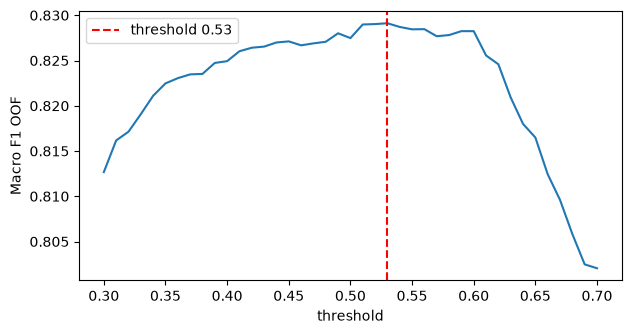

confusion matrix [[TN, FP], [FN, TP]]
[[16745  1620]
 [ 2396  6548]]
F1 kelas 0, kelas 1 [0.8929 0.7653]


In [18]:
thr_grid = np.round(np.arange(0.30, 0.71, 0.01), 2)
plt.figure(figsize=(7, 3.5))
plt.plot(thr_grid, [macro_f1(y, (oof_dt >= t).astype(int)) for t in thr_grid])
plt.axvline(DT_THRESHOLD, color='red', linestyle='--', label=f'threshold {DT_THRESHOLD}')
plt.xlabel('threshold')
plt.ylabel('Macro F1 OOF')
plt.legend()
plt.show()

pred_dt = (oof_dt >= DT_THRESHOLD).astype(int)
print('confusion matrix [[TN, FP], [FN, TP]]')
print(confusion_matrix(y, pred_dt))
print('F1 kelas 0, kelas 1', f1_per_class(y, pred_dt).round(4))

#### Insights

> Kurva Macro F1 terhadap threshold cukup landai di sekitar 0,45 sampai 0,55, jadi pilihan threshold tidak terlalu sensitif. F1 kelas batal (0,77) masih jauh di bawah kelas tidak batal (0,89), dan kesalahan terbesar adalah False Negative.

Model from scratch, preprocessing, dan fungsi bantu ditulis langsung di notebook ini (bagian **Kode From Scratch**), jadi notebook bisa dijalankan tanpa file lain.

In [19]:
k_values = [5, 11, 21, 31, 51]
knn_rows = []
for weights in ['uniform', 'distance']:
    oofs = {k: np.zeros(len(y)) for k in k_values}
    for tr_idx, va_idx in folds:
        prep = KNNPreprocessor()
        X_tr = prep.fit_transform(train.iloc[tr_idx])
        X_va = prep.transform(train.iloc[va_idx])
        knn = KNN(k=max(k_values), weights=weights).fit(X_tr, y[tr_idx])
        dist, idx = knn.kneighbors(X_va)
        for k in k_values:
            oofs[k][va_idx] = knn.proba_from_neighbors(dist, idx, k)
    for k in k_values:
        knn_rows.append(dict(weights=weights, k=k, **report('KNN', oofs[k])))

knn_grid = pd.DataFrame(knn_rows)
knn_grid.pivot(index='k', columns='weights', values='oof_macro_f1')

weights,distance,uniform
k,,
5,0.7698,0.7504
11,0.7810,0.7557
21,0.7846,0.7544
31,0.7852,0.7512
51,0.7869,0.7492


#### Insights

> Voting terbobot jarak selalu lebih baik dari voting biasa, dan skornya naik pelan seiring k. Meski begitu KNN masih tertinggal sekitar 0,04 dari Decision Tree, kemungkinan karena seluruh fitur, termasuk indikator missing dan one-hot, diberi bobot yang sama dalam perhitungan jarak.

## 5.4 Perbandingan dengan scikit-learn

Model scikit-learn dievaluasi dengan fold dan threshold yang sama. Karena `DecisionTreeClassifier` tidak menerima teks, data diberikan dalam bentuk hasil `KNNPreprocessor`. Varian ID3, C4.5, dan CART mengikuti ketentuan spesifikasi.

In [20]:
# Bungkus model scikit-learn agar predict_proba mengembalikan satu kolom seperti model from scratch.
class SklearnWrapper:
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]


best_k = 21
sk_models = {
    'sklearn ID3 (entropy)'          : lambda: DecisionTreeClassifier(criterion='entropy', max_depth=12, min_samples_leaf=10, random_state=CFG.SEED),
    'sklearn C4.5 (entropy + ccp)'   : lambda: DecisionTreeClassifier(criterion='entropy', ccp_alpha=1e-4, random_state=CFG.SEED),
    'sklearn CART (gini)'            : lambda: DecisionTreeClassifier(criterion='gini', max_depth=12, min_samples_leaf=10, random_state=CFG.SEED),
    f'sklearn KNN uniform k={best_k}': lambda: KNeighborsClassifier(n_neighbors=best_k),
}
rows = [res_dt]
rows.append(report('DT from scratch (entropy)', cross_val_proba(
    lambda: DecisionTree(criterion='entropy', max_depth=12, min_samples_leaf=10),
    lambda: TreePreprocessor(), train, y, folds)))
rows.append(knn_grid.query('weights == "uniform" and k == @best_k').iloc[0][
    ['threshold', 'oof_macro_f1', 'fold_mean', 'fold_std']].to_dict() | {'model': f'KNN from scratch uniform k={best_k}'})
for name, make in sk_models.items():
    rows.append(report(name, cross_val_proba(lambda: SklearnWrapper(make()),
                                             lambda: KNNPreprocessor(), train, y, folds)))

comparison = pd.DataFrame(rows).set_index('model').sort_values('oof_macro_f1', ascending=False)
comparison

,threshold,oof_macro_f1,fold_mean,fold_std
model,,,,
sklearn CART (gini),0.51,0.8299,0.8299,0.0042
DT from scratch (gini),0.53,0.8291,0.8291,0.0076
DT from scratch (entropy),0.42,0.8283,0.8283,0.0056
sklearn ID3 (entropy),0.47,0.8270,0.8269,0.0051
sklearn C4.5 (entropy + ccp),0.72,0.8106,0.8106,0.0044
KNN from scratch uniform k=21,0.39,0.7544,0.7544,0.0033
sklearn KNN uniform k=21,0.39,0.7544,0.7544,0.0033


#### Insights

> KNN from scratch menghasilkan skor yang sama persis dengan scikit-learn, sehingga implementasinya sudah benar. Decision Tree from scratch setara dengan CART scikit-learn (selisih 0,0008) walaupun tanpa one-hot dan tanpa imputasi, karena kategori dan missing value ditangani langsung di dalam pohon. Varian C4.5 dengan `ccp_alpha` lebih rendah karena pohon dibiarkan tumbuh tanpa batas kedalaman. Decision Tree from scratch dipilih sebagai model baseline untuk submission.

---

# Submission <a name="6"></a>

---

## 6.1 Training Final

Preprocessor dan Decision Tree dilatih ulang dengan seluruh data train memakai `CFG.DT_PARAMS`. Threshold diambil dari hasil OOF pada bagian 5.2.

kedalaman 12  jumlah daun 459  threshold 0.53


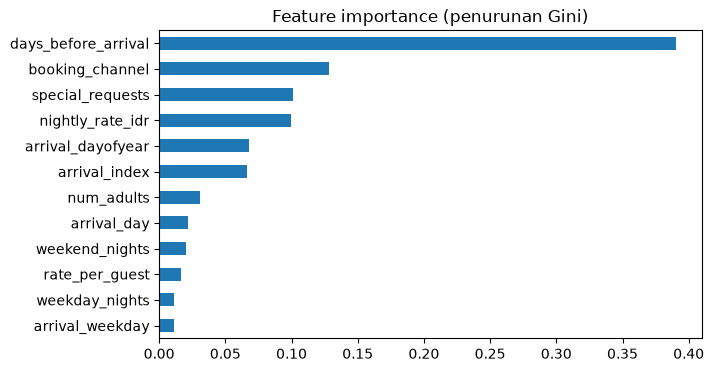

In [21]:
prep_final = TreePreprocessor().fit(train)
dt_final = DecisionTree(**CFG.DT_PARAMS).fit(prep_final.transform(train), y)
print('kedalaman', dt_final.get_depth(), ' jumlah daun', dt_final.get_n_leaves(), ' threshold', DT_THRESHOLD)

importance = pd.Series(dt_final.feature_importances_, index=dt_final.feature_names_)
importance.sort_values().tail(12).plot.barh(figsize=(7, 4), title='Feature importance (penurunan Gini)')
plt.show()

## 6.2 Save dan Load Model

Preprocessor, model, dan threshold disimpan bersama dalam satu file pickle, lalu dimuat kembali untuk prediksi.

In [22]:
save_model({'preprocessor': prep_final, 'model': dt_final, 'threshold': DT_THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)
print('model tersimpan di', CFG.MODEL_PATH)

model tersimpan di output/models/dt_baseline_fe.pkl


## 6.3 Prediksi dan File Submission

Data test hanya di-transform dengan preprocessor yang sudah di-fit pada train.

In [ ]:
X_test = bundle['preprocessor'].transform(test_raw)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({'id': test_raw['id'], 'is_canceled': test_pred})
assert len(submission) == len(sample) and set(submission['id']) == set(sample['id'])
submission.to_csv(CFG.SUB_PATH, index=False)

print(submission['is_canceled'].value_counts(normalize=True).round(4))
submission.head()

is_canceled
0    0.7092
1    0.2908
Name: proportion, dtype: float64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0
